# Outfield player comparisons

Compare six pools using current roster eligibility and one historical performance season. Goalkeepers are excluded.

| Pool | Qualifying roles (OR membership) |
|---|---|
| Centre backs | Dc, B |
| Fullbacks | Dd, Ds, E |
| Defensive midfielders | M |
| Central midfielders | C |
| Attacking players | W, T, A |
| Strikers | Pc |

**Multi-role handling:** one player appears once per qualifying pool. Dd/Ds has one fullback point; C/T appears in central midfield and attack; A/Pc appears in attack and striker. Those are comparison memberships, not permission to field one player twice. W/T/A is a broad comparison pool, not a single interchangeable formation slot. Full role combinations determine colors, consistently across the six plots in this run. B qualifies for centre backs and E qualifies for fullbacks, including players with only those roles.

## 1. Extract player-season metrics

Default: **2025–26 performance**, **current 2026–27 eligibility**, **rated matches / 38 ≥30%** (at least 12 rated observations). Change the parameters below to examine another season separately. Rated coverage is observed contribution, not actual appearance probability or injury risk. Players below the filter are excluded from this analysis; missing history does not imply poor ability.

The SQL joins each player-season row to the eligible groups using array overlap, without exploding individual roles. The inclusive coverage filter applies equally to all pools. Published FV already includes event effects; no bonuses or card adjustments are added here.

In [2]:
%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from project.analysis.queries import connect_database, fetch_group_metrics, GROUP_METRICS_QUERY
from project.analysis.outfield_comparison import GROUPS, TABLE_COLUMNS, group_table, plot_outfield_comparison
from project.etl.import_players import ROOT

PERFORMANCE_SEASON = 2025
MIN_COVERAGE = 0.30
OUTPUT_DIR = ROOT / "img" / "outfield-comparison"
print(GROUP_METRICS_QUERY)
print({"season": PERFORMANCE_SEASON, "min_fraction": MIN_COVERAGE})


    SELECT m.*, groups.group_key,
           array_to_string(ARRAY(SELECT role FROM unnest(m.roles) AS role
                                 ORDER BY role), '/') AS role_combination
    FROM player_season_metrics m
    JOIN (VALUES
        ('dc', ARRAY['Dc', 'B']::text[]),
        ('fullbacks', ARRAY['Dd', 'Ds', 'E']::text[]),
        ('m', ARRAY['M']::text[]),
        ('c', ARRAY['C']::text[]),
        ('attack', ARRAY['W', 'T', 'A']::text[]),
        ('pc', ARRAY['Pc']::text[])
    ) AS groups(group_key, eligible_roles)
      ON m.roles && groups.eligible_roles
    WHERE m.performance_season = :season
      AND m.rated_season_fraction >= :min_fraction
    ORDER BY groups.group_key, m.mean_fv DESC NULLS LAST,
             m.rated_matches DESC, m.player_name, m.player_id, m.source_id

{'season': 2025, 'min_fraction': 0.3}


In [3]:
engine = connect_database()
try:
    players = fetch_group_metrics(
        engine, PERFORMANCE_SEASON,
        min_rated_season_fraction=MIN_COVERAGE,
    )
finally:
    engine.dispose()

print("Unique players:", len(players[["player_id", "source_id"]].drop_duplicates()))
print("Current eligibility season(s):", sorted(players["eligibility_season"].unique()))
display(players.groupby(["group_key", "coverage_status"]).size().rename("players").to_frame())
assert not players.duplicated(["player_id", "source_id", "group_key"]).any()
assert players["rated_season_fraction"].ge(MIN_COVERAGE).all()

Unique players: 258
Current eligibility season(s): [np.int64(2026)]


,,players
group_key,coverage_status,
attack,complete,80
c,complete,76
dc,complete,62
fullbacks,complete,64
m,complete,39
pc,complete,26


## 2. Read the plots and tables

All six scatterplots show rated-season coverage horizontally and mean FV vertically. The coverage scale is shared; each vertical scale fits the vote range of players in that group, making within-group differences easier to see. Compare numeric FV values across groups rather than point heights. The dotted line marks the coverage threshold. Names identify the ten highest mean FV players, breaking ties by rated matches descending, then name and IDs. Full role combinations have the same color across plots; colors may change when selecting a different dataset.

Tables list **every retained player**, including missing FV values. Rates are fractions (0.30 = 30%). `fv_ge6_rate` measures consistency as the share of valid FV ≥6; `fv_p90` is each player's within-season upside. Goals/assists per rated match exclude observations where that event is unknown. Bonus rate requires known goals, scored penalties and assists; card rate requires both card flags. Event sample columns expose the denominators. Missing values stay missing, rather than becoming zero.

Complete fixture coverage does not guarantee every player/event observation is available. These charts describe historical profiles, not future performance or auction value; tier boundaries remain to be decided after examining the distributions.

In [4]:
figures = plot_outfield_comparison(
    players, performance_season=PERFORMANCE_SEASON,
    min_rated_season_fraction=MIN_COVERAGE,
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for key, figure in figures.items():
    figure.savefig(OUTPUT_DIR / f"{key}.png", dpi=160, bbox_inches="tight")
    plt.close(figure)  # Explicit display below keeps each chart beside its table.

### Centre backs

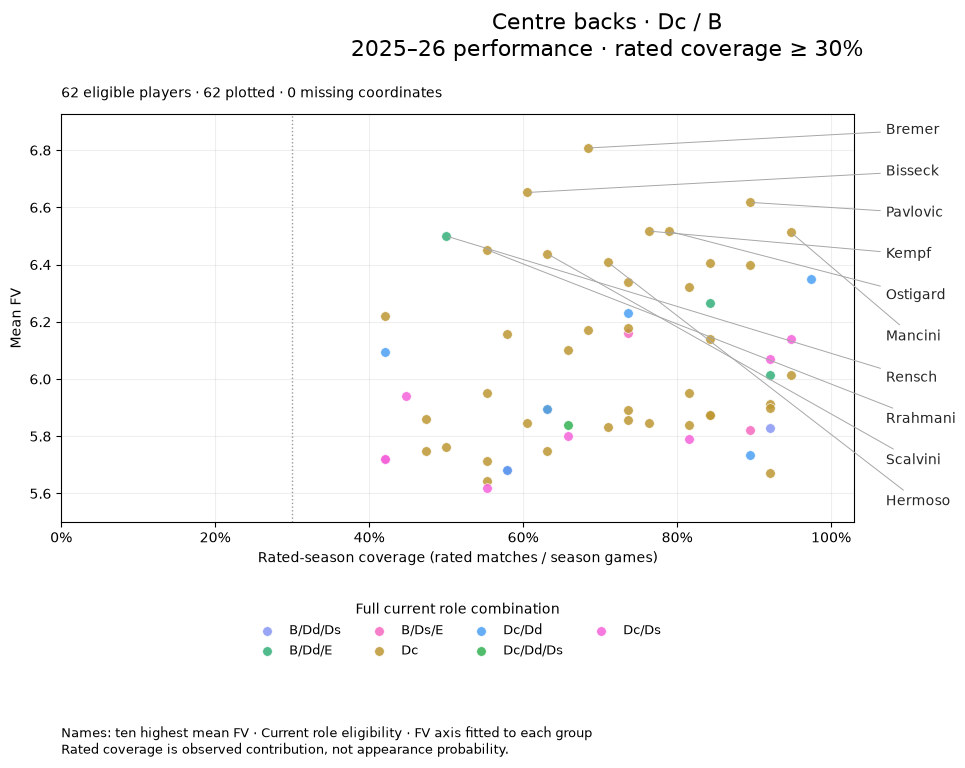

,player_id,player_name,current_team,role_combination,eligibility_season,performance_season,mean_fv,rated_season_fraction,rated_matches,fv_matches,fv_season_fraction,fv_ge6_rate,fv_p90,source_goals_per_rated_match,assists_per_rated_match,bonus_rate,card_rate,goal_sample,assist_sample,bonus_sample,card_sample,evidence_status,coverage_status
0,68,Bremer,Juventus,Dc,2026,2025,6.808,0.684,26,26,0.684,0.731,9.50,0.154,0.115,0.192,0.192,26,26,26,26,larger_sample,complete
1,78,Bisseck,Inter,Dc,2026,2025,6.652,0.605,23,23,0.605,0.783,9.10,0.130,0.087,0.217,0.087,23,23,23,23,larger_sample,complete
2,74,Pavlovic,Milan,Dc,2026,2025,6.618,0.895,34,34,0.895,0.794,9.35,0.147,0.000,0.147,0.118,34,34,34,34,larger_sample,complete
3,152,Kempf,Como,Dc,2026,2025,6.517,0.763,29,29,0.763,0.828,9.50,0.138,0.034,0.172,0.103,29,29,29,29,larger_sample,complete
4,81,Ostigard,Genoa,Dc,2026,2025,6.517,0.789,30,30,0.789,0.667,10.00,0.167,0.000,0.167,0.233,30,30,30,30,larger_sample,complete
5,69,Mancini,Roma,Dc,2026,2025,6.514,0.947,36,36,0.947,0.806,7.25,0.111,0.056,0.139,0.250,36,36,36,36,larger_sample,complete
6,180,Rensch,Roma,B/Dd/E,2026,2025,6.500,0.500,19,19,0.500,0.684,7.50,0.053,0.211,0.263,0.053,19,19,19,19,larger_sample,complete
7,71,Rrahmani,Napoli,Dc,2026,2025,6.452,0.553,21,21,0.553,0.762,7.00,0.095,0.000,0.095,0.143,21,21,21,21,larger_sample,complete
8,84,Scalvini,Atalanta,Dc,2026,2025,6.438,0.632,24,24,0.632,0.708,8.95,0.125,0.042,0.167,0.083,24,24,24,24,larger_sample,complete
9,82,Hermoso,Roma,Dc,2026,2025,6.407,0.711,27,27,0.711,0.667,8.80,0.111,0.074,0.148,0.333,27,27,27,27,larger_sample,complete


In [5]:
display(figures["dc"])
table = group_table(players, "dc")[TABLE_COLUMNS]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(3))

### Fullbacks

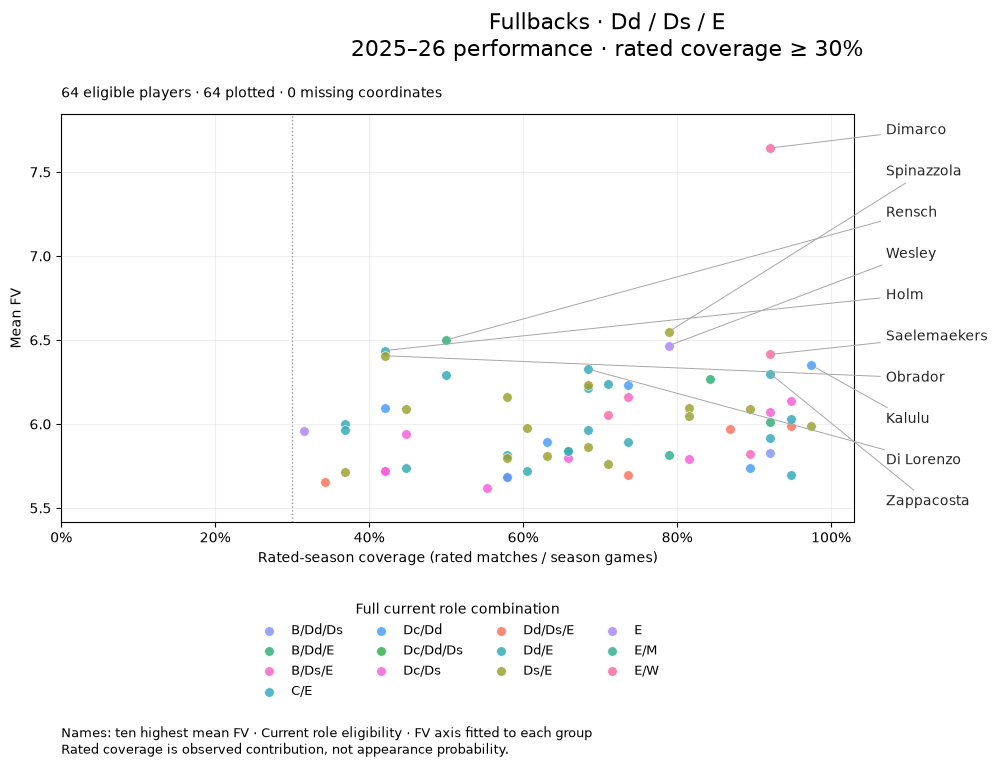

,player_id,player_name,current_team,role_combination,eligibility_season,performance_season,mean_fv,rated_season_fraction,rated_matches,fv_matches,fv_season_fraction,fv_ge6_rate,fv_p90,source_goals_per_rated_match,assists_per_rated_match,bonus_rate,card_rate,goal_sample,assist_sample,bonus_sample,card_sample,evidence_status,coverage_status
0,65,Dimarco,Inter,E/W,2026,2025,7.643,0.921,35,35,0.921,0.886,10.30,0.200,0.486,0.514,0.086,35,35,35,35,larger_sample,complete
1,98,Spinazzola,Napoli,Ds/E,2026,2025,6.550,0.789,30,30,0.789,0.800,7.70,0.100,0.100,0.167,0.033,30,30,30,30,larger_sample,complete
2,180,Rensch,Roma,B/Dd/E,2026,2025,6.500,0.500,19,19,0.500,0.684,7.50,0.053,0.211,0.263,0.053,19,19,19,19,larger_sample,complete
3,66,Wesley,Roma,E,2026,2025,6.467,0.789,30,30,0.789,0.667,10.00,0.167,0.000,0.167,0.233,30,30,30,30,larger_sample,complete
4,127,Holm,Bologna,Dd/E,2026,2025,6.438,0.421,16,16,0.421,0.688,7.75,0.062,0.250,0.312,0.125,16,16,16,16,larger_sample,complete
5,285,Saelemaekers,Milan,E/W,2026,2025,6.414,0.921,35,35,0.921,0.714,7.80,0.086,0.086,0.171,0.143,35,35,35,35,larger_sample,complete
6,144,Obrador,Sassuolo,Ds/E,2026,2025,6.406,0.421,16,16,0.421,0.688,7.75,0.062,0.188,0.250,0.062,16,16,16,16,larger_sample,complete
7,73,Kalulu,Juventus,Dc/Dd,2026,2025,6.351,0.974,37,37,0.974,0.730,7.50,0.054,0.108,0.162,0.081,37,37,37,37,larger_sample,complete
8,80,Di Lorenzo,Napoli,Dd/E,2026,2025,6.327,0.684,26,26,0.684,0.769,7.00,0.077,0.038,0.115,0.038,26,26,26,26,larger_sample,complete
9,91,Zappacosta,Atalanta,Dd/E,2026,2025,6.300,0.921,35,35,0.921,0.686,7.10,0.086,0.029,0.114,0.086,35,35,35,35,larger_sample,complete


In [6]:
display(figures["fullbacks"])
table = group_table(players, "fullbacks")[TABLE_COLUMNS]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(3))

### Defensive midfielders

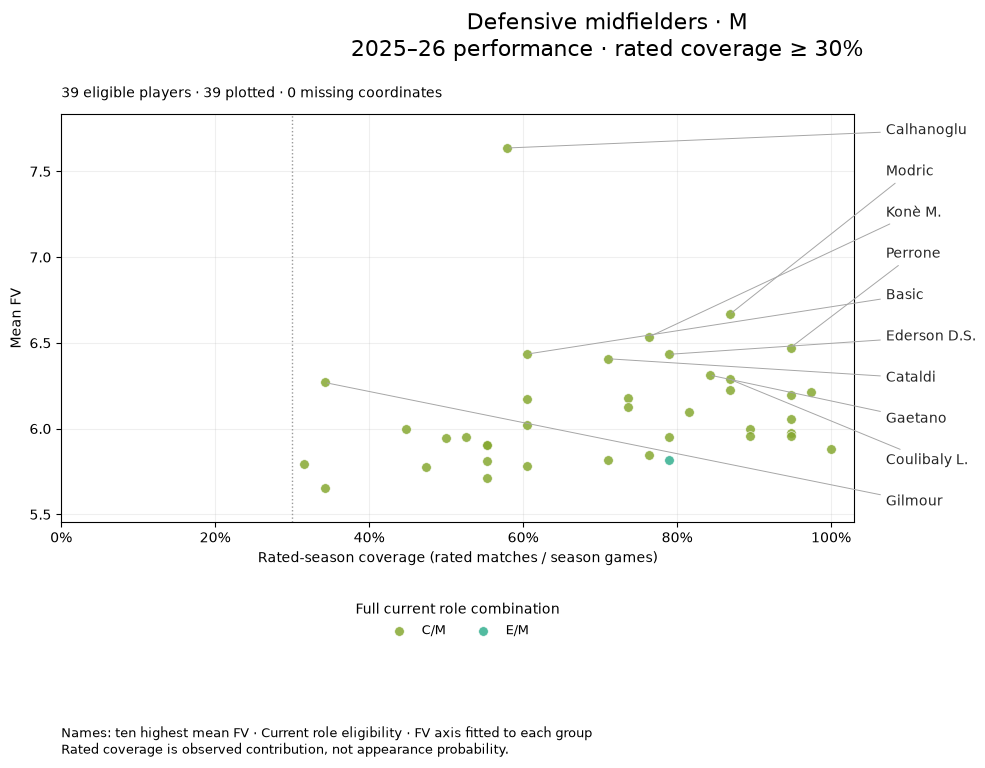

,player_id,player_name,current_team,role_combination,eligibility_season,performance_season,mean_fv,rated_season_fraction,rated_matches,fv_matches,fv_season_fraction,fv_ge6_rate,fv_p90,source_goals_per_rated_match,assists_per_rated_match,bonus_rate,card_rate,goal_sample,assist_sample,bonus_sample,card_sample,evidence_status,coverage_status
0,255,Calhanoglu,Inter,C/M,2026,2025,7.636,0.579,22,22,0.579,0.864,11.35,0.227,0.182,0.455,0.318,22,22,22,22,larger_sample,complete
1,276,Modric,Milan,C/M,2026,2025,6.667,0.868,33,33,0.868,0.939,7.50,0.061,0.091,0.152,0.121,33,33,33,33,larger_sample,complete
2,294,Konè M.,Roma,C/M,2026,2025,6.534,0.763,29,29,0.763,0.793,7.60,0.069,0.103,0.172,0.069,29,29,29,29,larger_sample,complete
3,290,Perrone,Como,C/M,2026,2025,6.472,0.947,36,36,0.947,0.694,8.75,0.083,0.111,0.167,0.222,36,36,36,36,larger_sample,complete
4,359,Basic,Venezia,C/M,2026,2025,6.435,0.605,23,23,0.605,0.652,7.90,0.087,0.130,0.217,0.043,23,23,23,23,larger_sample,complete
5,273,Ederson D.S.,Atalanta,C/M,2026,2025,6.433,0.789,30,30,0.789,0.833,7.00,0.033,0.033,0.067,0.100,30,30,30,30,larger_sample,complete
6,387,Cataldi,Lazio,C/M,2026,2025,6.407,0.711,27,27,0.711,0.667,8.60,0.037,0.111,0.222,0.222,27,27,27,27,larger_sample,complete
7,319,Gaetano,Atalanta,C/M,2026,2025,6.312,0.842,32,32,0.842,0.719,7.50,0.062,0.125,0.188,0.125,32,32,32,32,larger_sample,complete
8,329,Coulibaly L.,Lecce,C/M,2026,2025,6.288,0.868,33,33,0.868,0.697,7.70,0.091,0.030,0.121,0.121,33,33,33,33,larger_sample,complete
9,410,Gilmour,Napoli,C/M,2026,2025,6.269,0.342,13,13,0.342,0.769,6.50,0.077,0.000,0.077,0.077,13,13,13,13,limited_sample,complete


In [7]:
display(figures["m"])
table = group_table(players, "m")[TABLE_COLUMNS]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(3))

### Central midfielders

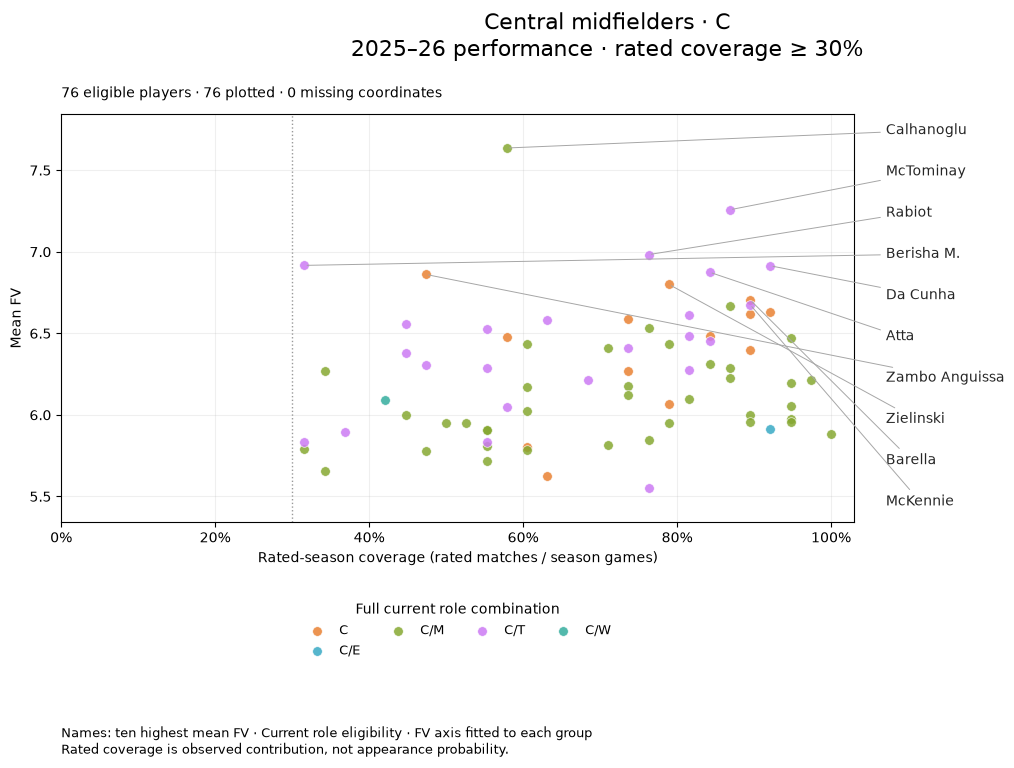

,player_id,player_name,current_team,role_combination,eligibility_season,performance_season,mean_fv,rated_season_fraction,rated_matches,fv_matches,fv_season_fraction,fv_ge6_rate,fv_p90,source_goals_per_rated_match,assists_per_rated_match,bonus_rate,card_rate,goal_sample,assist_sample,bonus_sample,card_sample,evidence_status,coverage_status
0,255,Calhanoglu,Inter,C/M,2026,2025,7.636,0.579,22,22,0.579,0.864,11.35,0.227,0.182,0.455,0.318,22,22,22,22,larger_sample,complete
1,256,McTominay,Napoli,C/T,2026,2025,7.258,0.868,33,33,0.868,0.848,10.00,0.303,0.061,0.333,0.030,33,33,33,33,larger_sample,complete
2,259,Rabiot,Milan,C/T,2026,2025,6.983,0.763,29,29,0.763,0.759,10.00,0.207,0.138,0.276,0.172,29,29,29,29,larger_sample,complete
3,389,Berisha M.,Lecce,C/T,2026,2025,6.917,0.316,12,12,0.316,0.667,9.50,0.167,0.250,0.333,0.000,12,12,12,12,limited_sample,complete
4,262,Da Cunha,Como,C/T,2026,2025,6.914,0.921,35,35,0.921,0.829,9.80,0.057,0.114,0.229,0.114,35,35,35,35,larger_sample,complete
5,268,Atta,Fiorentina,C/T,2026,2025,6.875,0.842,32,32,0.842,0.750,9.95,0.156,0.094,0.156,0.094,32,32,32,32,larger_sample,complete
6,292,Zambo Anguissa,Napoli,C,2026,2025,6.861,0.474,18,18,0.474,0.611,10.15,0.222,0.056,0.278,0.056,18,18,18,18,larger_sample,complete
7,275,Zielinski,Inter,C,2026,2025,6.800,0.789,30,30,0.789,0.767,10.00,0.167,0.067,0.267,0.100,30,30,30,30,larger_sample,complete
8,263,Barella,Inter,C,2026,2025,6.706,0.895,34,34,0.895,0.676,8.90,0.088,0.265,0.324,0.206,34,34,34,34,larger_sample,complete
9,265,McKennie,Juventus,C/T,2026,2025,6.676,0.895,34,34,0.895,0.735,9.70,0.147,0.176,0.294,0.147,34,34,34,34,larger_sample,complete


In [8]:
display(figures["c"])
table = group_table(players, "c")[TABLE_COLUMNS]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(3))

### Attacking players

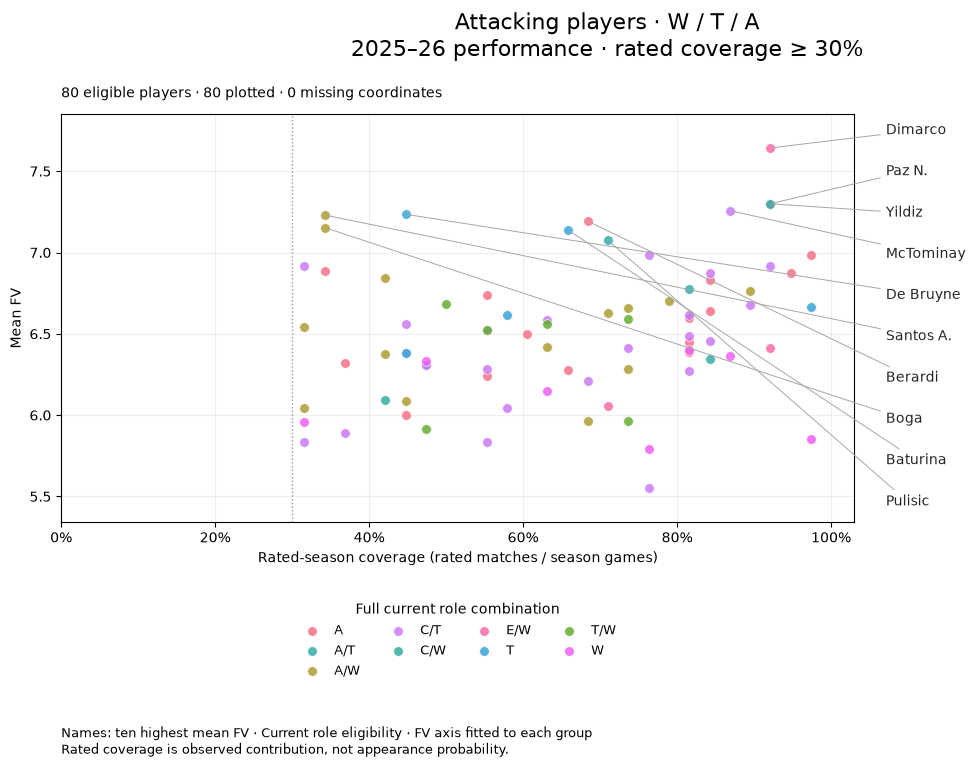

,player_id,player_name,current_team,role_combination,eligibility_season,performance_season,mean_fv,rated_season_fraction,rated_matches,fv_matches,fv_season_fraction,fv_ge6_rate,fv_p90,source_goals_per_rated_match,assists_per_rated_match,bonus_rate,card_rate,goal_sample,assist_sample,bonus_sample,card_sample,evidence_status,coverage_status
0,65,Dimarco,Inter,E/W,2026,2025,7.643,0.921,35,35,0.921,0.886,10.30,0.200,0.486,0.514,0.086,35,35,35,35,larger_sample,complete
1,254,Paz N.,Como,A/T,2026,2025,7.300,0.921,35,35,0.921,0.743,10.30,0.343,0.143,0.371,0.143,35,35,35,35,larger_sample,complete
2,455,Yildiz,Juventus,A,2026,2025,7.300,0.921,35,35,0.921,0.886,10.00,0.257,0.171,0.343,0.057,35,35,35,35,larger_sample,complete
3,256,McTominay,Napoli,C/T,2026,2025,7.258,0.868,33,33,0.868,0.848,10.00,0.303,0.061,0.333,0.030,33,33,33,33,larger_sample,complete
4,266,De Bruyne,Napoli,T,2026,2025,7.235,0.447,17,17,0.447,0.765,10.00,0.118,0.118,0.353,0.059,17,17,17,17,larger_sample,complete
5,466,Santos A.,Napoli,A/W,2026,2025,7.231,0.342,13,13,0.342,0.769,10.40,0.308,0.000,0.308,0.077,13,13,13,13,limited_sample,complete
6,457,Berardi,Sassuolo,A,2026,2025,7.192,0.684,26,26,0.684,0.692,10.00,0.231,0.154,0.346,0.115,26,26,26,26,larger_sample,complete
7,492,Boga,Juventus,A/W,2026,2025,7.154,0.342,13,13,0.342,0.692,10.00,0.308,0.077,0.385,0.077,13,13,13,13,limited_sample,complete
8,260,Baturina,Como,T,2026,2025,7.140,0.658,25,25,0.658,0.760,10.00,0.240,0.120,0.280,0.000,25,25,25,25,larger_sample,complete
9,258,Pulisic,Milan,A/T,2026,2025,7.074,0.711,27,27,0.711,0.556,10.80,0.296,0.148,0.296,0.000,27,27,27,27,larger_sample,complete


In [9]:
display(figures["attack"])
table = group_table(players, "attack")[TABLE_COLUMNS]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(3))

### Strikers

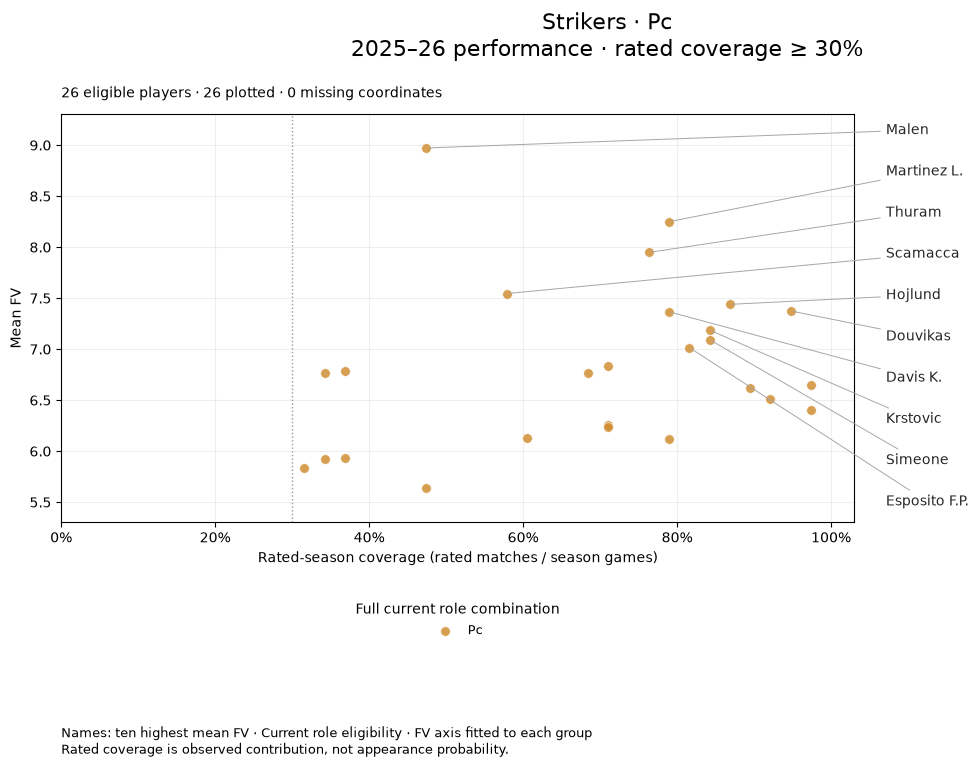

,player_id,player_name,current_team,role_combination,eligibility_season,performance_season,mean_fv,rated_season_fraction,rated_matches,fv_matches,fv_season_fraction,fv_ge6_rate,fv_p90,source_goals_per_rated_match,assists_per_rated_match,bonus_rate,card_rate,goal_sample,assist_sample,bonus_sample,card_sample,evidence_status,coverage_status
0,446,Malen,Roma,Pc,2026,2025,8.972,0.474,18,18,0.474,0.833,13.65,0.611,0.111,0.556,0.056,18,18,18,18,larger_sample,complete
1,447,Martinez L.,Inter,Pc,2026,2025,8.250,0.789,30,30,0.789,0.667,11.50,0.567,0.200,0.567,0.133,30,30,30,30,larger_sample,complete
2,448,Thuram,Inter,Pc,2026,2025,7.948,0.763,29,29,0.763,0.793,10.50,0.448,0.207,0.517,0.069,29,29,29,29,larger_sample,complete
3,456,Scamacca,Atalanta,Pc,2026,2025,7.545,0.579,22,22,0.579,0.545,13.15,0.364,0.045,0.364,0.091,22,22,22,22,larger_sample,complete
4,449,Hojlund,Napoli,Pc,2026,2025,7.439,0.868,33,33,0.868,0.636,11.30,0.333,0.152,0.394,0.030,33,33,33,33,larger_sample,complete
5,454,Douvikas,Como,Pc,2026,2025,7.375,0.947,36,36,0.947,0.611,10.00,0.361,0.028,0.361,0.000,36,36,36,36,larger_sample,complete
6,458,Davis K.,Udinese,Pc,2026,2025,7.367,0.789,30,30,0.789,0.667,10.05,0.200,0.133,0.433,0.167,30,30,30,30,larger_sample,complete
7,459,Krstovic,Atalanta,Pc,2026,2025,7.188,0.842,32,32,0.842,0.688,10.00,0.312,0.156,0.344,0.125,32,32,32,32,larger_sample,complete
8,469,Simeone,Torino,Pc,2026,2025,7.094,0.842,32,32,0.842,0.500,10.00,0.344,0.000,0.344,0.031,32,32,32,32,larger_sample,complete
9,461,Esposito F.P.,Inter,Pc,2026,2025,7.016,0.816,31,31,0.816,0.806,10.00,0.226,0.097,0.323,0.032,31,31,31,31,larger_sample,complete


In [10]:
display(figures["pc"])
table = group_table(players, "pc")[TABLE_COLUMNS]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table.round(3))